#Today's Learning Plan
- Supervised Learning revision
- Regression — concepts and algorithms
- Classification — concepts and algorithms
- Regression vs Classification differences
- Practical 1: Linear Regression
- Practical 2: Classification using Logistic Regression
- Model predictions
- Model evaluation
- Day 62 revision and summary

#Step 1 — Import Required Libraries

In [1]:

# Day 62 - Supervised Learning
# Regression vs Classification

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import sklearn

print("NumPy Version:", np.__version__)
print("Pandas Version:", pd.__version__)
print("Scikit-learn Version:", sklearn.__version__)

print("\nDay 62 Environment Ready!")

NumPy Version: 2.4.6
Pandas Version: 2.2.3
Scikit-learn Version: 1.6.1

Day 62 Environment Ready!


#Step 2: Supervised Learning

#What is Supervised Learning?
###Supervised Learning is a type of Machine Learning in which a model learns from labelled data, meaning the dataset contains both input features and their correct outputs.

###The model learns the relationship between inputs and outputs and uses that knowledge to predict results for new data.

#Simple example

##Suppose we have this dataset:

###Study Hours 	Exam Result

#2             	Fail

#4            	Pass


#6             	Pass

#8             	Pass

#Here:
- Input (X) = Study Hours
- Output (y) = Exam Result
##The model learns from these examples and predicts whether a new student might pass or fail.

#Two Main Types of Supervised Learning
##1. Regression

####Predicts numerical values.

Examples:
- House price
- Employee salary
- Bike rental demand
##2. Classification

####Predicts categories.

Examples:
- Spam / Not Spam
- Pass / Fail
- Churn / No Churn

#Step 3 — Understand the Difference
##Regression
###Output: Numerical value

##Classification
###Output: Category

Regression	           Classification

Continuous values	     Class labels


Predicts quantity	     Predicts category


MAE, MSE, R²	         Accuracy, Precision, Recall, F1

Important connection with your previous projects:
- Telco Customer Churn → Classification (predicting Yes/No).
- Bike Sharing Demand → Regression (predicting rental count).

#Step 4: Regression in Machine Learning

#1. What is Regression?
###Definition (Interview-ready):

##Regression is a Supervised Machine Learning technique used to predict continuous numerical values by identifying relationships between input features and a target variable.

#In simple words: Regression predicts how much or how many.
##Real-world examples
- Predicting house prices.
- Predicting employee salaries.
- Predicting monthly sales.
- Predicting bike rental demand.
- Predicting temperature.

#Types of Regression Algorithms:
##1. Linear Regression

##2. Decision Tree Regressor

##3. Random Forest Regressor

#3. Important Regression Formula
In Linear Regression:
\[
y = mx+c
\]

Where:
- y = Predicted output
- x = Input feature
- m = Slope
- c = Intercept

Yesterday, our model learned:
\[
Price = 0.03 \times Area
\]

For an area of 1000 sq. ft.:
\[
Price = 0.03 \times 1000 = 30
\]

Predicted price = ₹30 lakh.

#Step 6 — Practical: Linear Regression
Now let's build another regression model using a new dataset.

Dataset: Student Study Hours vs Exam Scores.

Our objective is to predict a student's exam score based on study hours.

##Step 1: Create the dataset

In [2]:

import pandas as pd

# Student study hours and exam scores

data = {
    "Study_Hours": [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
    "Exam_Score": [35, 40, 50, 55, 60, 65, 70, 80, 85, 95]
}

df = pd.DataFrame(data)

print(df)

   Study_Hours  Exam_Score
0            1          35
1            2          40
2            3          50
3            4          55
4            5          60
5            6          65
6            7          70
7            8          80
8            9          85
9           10          95


##Step 2: Separate Features (X) and Target (y)

In [3]:
# Separate input features (X) and target (y)

X = df[["Study_Hours"]]
y = df["Exam_Score"]

print("Features (X):")
print(X)

print("\nTarget (y):")
print(y)

Features (X):
   Study_Hours
0            1
1            2
2            3
3            4
4            5
5            6
6            7
7            8
8            9
9           10

Target (y):
0    35
1    40
2    50
3    55
4    60
5    65
6    70
7    80
8    85
9    95
Name: Exam_Score, dtype: int64


##Step 3: Train-Test Split

In [4]:
from sklearn.model_selection import train_test_split

# Split dataset into 80% training and 20% testing

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training Features:")
print(X_train)

print("\nTesting Features:")
print(X_test)

print("\nTraining Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

Training Features:
   Study_Hours
5            6
0            1
7            8
2            3
9           10
4            5
3            4
6            7

Testing Features:
   Study_Hours
8            9
1            2

Training Data Shape: (8, 1)
Testing Data Shape: (2, 1)


##Step 4: Train the Linear Regression Model

In [5]:
from sklearn.linear_model import LinearRegression

# Create Linear Regression model
model = LinearRegression()

# Train the model
model.fit(X_train, y_train)

print("Linear Regression Model Trained Successfully!")
print("Slope (Coefficient):", model.coef_[0])
print("Intercept:", model.intercept_)

Linear Regression Model Trained Successfully!
Slope (Coefficient): 6.379310344827586
Intercept: 28.663793103448278


##Step 5: Predict Exam Scores

In [6]:
# Predict exam scores using testing data

y_pred = model.predict(X_test)

print("Actual Exam Scores:")
print(y_test.values)

print("\nPredicted Exam Scores:")
print(y_pred)

Actual Exam Scores:
[85 40]

Predicted Exam Scores:
[86.07758621 41.42241379]


##Step 6: Evaluate the Model

In [7]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Calculate evaluation metrics

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Model Evaluation Results")
print("------------------------")
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

Model Evaluation Results
------------------------
MAE: 1.2500000000000036
MSE: 1.5922265160523277
RMSE: 1.2618345834745248
R2 Score: 0.9968548612028596


##Step 7: Visualize Actual vs Predicted Scores

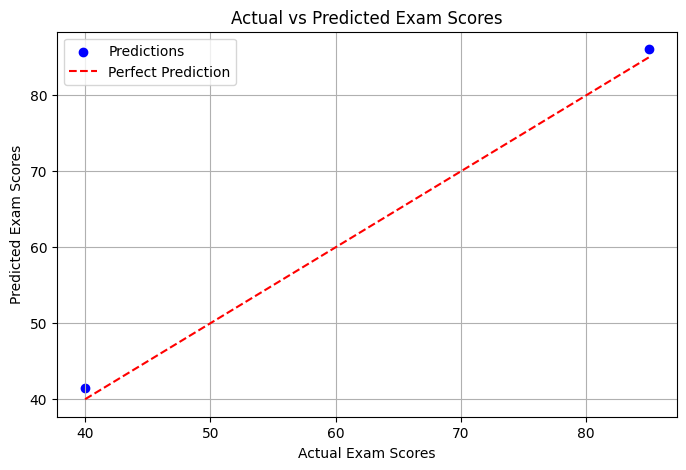

In [8]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred, color="blue", label="Predictions")

# Perfect prediction reference line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color="red",
    linestyle="--",
    label="Perfect Prediction"
)

plt.xlabel("Actual Exam Scores")
plt.ylabel("Predicted Exam Scores")
plt.title("Actual vs Predicted Exam Scores")

plt.legend()
plt.grid(True)
plt.show()

#Practical 2: Classification using Logistic Regression
##So far, we predicted numerical values (exam scores). Now we'll predict categories.

##Our objective: Predict whether a student will pass or fail based on study hours.

#Step 1: Create a Classification Dataset

In [9]:
import pandas as pd

# Student study hours and pass/fail results

data = {
    "Study_Hours": [1, 2, 3, 4, 5, 6, 7, 8, 9, 10,
                    1.5, 2.5, 3.5, 4.5, 5.5, 6.5, 7.5, 8.5],
    "Result": [0, 0, 0, 0, 0, 1, 1, 1, 1, 1,
               0, 0, 0, 0, 1, 1, 1, 1]
}

df_classification = pd.DataFrame(data)

print(df_classification)

    Study_Hours  Result
0           1.0       0
1           2.0       0
2           3.0       0
3           4.0       0
4           5.0       0
5           6.0       1
6           7.0       1
7           8.0       1
8           9.0       1
9          10.0       1
10          1.5       0
11          2.5       0
12          3.5       0
13          4.5       0
14          5.5       1
15          6.5       1
16          7.5       1
17          8.5       1


##Step 2: Separate Features (X) and Target (y)

In [10]:
# Separate input features (X) and target (y)

X = df_classification[["Study_Hours"]]
y = df_classification["Result"]

print("Features (X):")
print(X)

print("\nTarget (y):")
print(y)

print("\nDataset Shape:", df_classification.shape)

Features (X):
    Study_Hours
0           1.0
1           2.0
2           3.0
3           4.0
4           5.0
5           6.0
6           7.0
7           8.0
8           9.0
9          10.0
10          1.5
11          2.5
12          3.5
13          4.5
14          5.5
15          6.5
16          7.5
17          8.5

Target (y):
0     0
1     0
2     0
3     0
4     0
5     1
6     1
7     1
8     1
9     1
10    0
11    0
12    0
13    0
14    1
15    1
16    1
17    1
Name: Result, dtype: int64

Dataset Shape: (18, 2)


#Step 3: Train-Test Split

In [11]:
from sklearn.model_selection import train_test_split

# Split classification dataset

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

print("\nTraining Target Distribution:")
print(y_train.value_counts())

print("\nTesting Target Distribution:")
print(y_test.value_counts())

Training Data Shape: (14, 1)
Testing Data Shape: (4, 1)

Training Target Distribution:
Result
1    7
0    7
Name: count, dtype: int64

Testing Target Distribution:
Result
0    2
1    2
Name: count, dtype: int64


#Step 4: Train Logistic Regression Model

In [12]:
from sklearn.linear_model import LogisticRegression

# Create Logistic Regression model
model = LogisticRegression()

# Train the model
model.fit(X_train, y_train)

print("Logistic Regression Model Trained Successfully!")
print("Coefficient:", model.coef_[0][0])
print("Intercept:", model.intercept_[0])

Logistic Regression Model Trained Successfully!
Coefficient: 1.3188760853491674
Intercept: -6.9257025967288195


#Step 5: Make Predictions

In [13]:
# Predict class labels
y_pred = model.predict(X_test)

# Predict probability of passing
y_prob = model.predict_proba(X_test)[:, 1]

print("Testing Study Hours:")
print(X_test.values.flatten())

print("\nActual Results:")
print(y_test.values)

print("\nPredicted Probabilities (Pass):")
print(y_prob)

print("\nPredicted Results:")
print(y_pred)

Testing Study Hours:
[2.5 4.  8.  6.5]

Actual Results:
[0 0 1 1]

Predicted Probabilities (Pass):
[0.0258687  0.16108216 0.97405038 0.83848409]

Predicted Results:
[0 0 1 1]


#Step 6: Evaluate the Classification Model

In [14]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Calculate classification metrics

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Classification Model Evaluation")
print("--------------------------------")
print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Classification Model Evaluation
--------------------------------
Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1 Score: 1.0

Confusion Matrix:
[[2 0]
 [0 2]]
